In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from crafts_stack.halofit import *
from mytools.plot import plot_heatmap, plot_stack_fit_res, get_ticks_labels, set_ticks, plt, make_figure, plot_line

In [3]:
coord = get_coords()
mask = get_mask_sector4(coord)
x,y = coord

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

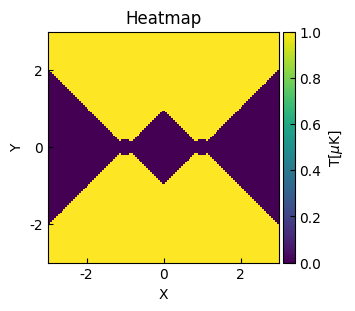

In [25]:
plot_heatmap(mask)

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

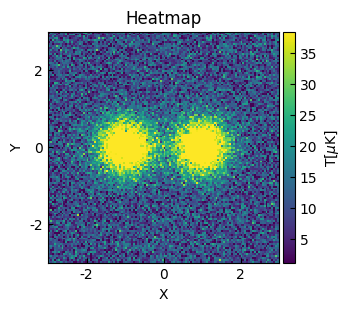

In [5]:
data = gen_test_data()
plot_heatmap(data)

In [11]:
fit_data, fit_info = get_halofit(x,y,data, mask=mask)

Initial double Gaussian model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [1]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [2]: <Const2D(amplitude=-11.5457783)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 ... y_stddev_1 theta_1     amplitude_2    
    ----------- -------- -------- ... ---------- ------- -------------------
           50.0     -1.0      0.0 ...        0.5     0.0 -11.545778303088209
Fitted double Gaussian model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=39.33859525, x_mean=-1.07963476, y_mean=0.01086866, x_stddev=0.3946648, y_stddev=0.51578916, theta=0.04040532)>

    [1]: <Gaussian2D(amplitude=42.03493728, x_mean=0.95377589, y_mean=0.00404369, 

array([<Axes: title={'center': 'Pairwise-stacked map'}, xlabel='X', ylabel='Y'>,
       <Axes: title={'center': 'Fitted halo contribution'}, xlabel='X'>,
       <Axes: title={'center': 'Filament signal'}, xlabel='X'>],
      dtype=object)

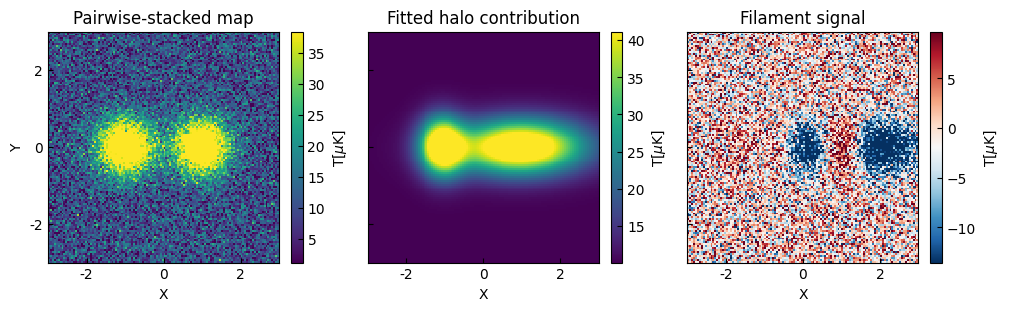

In [ ]:
res = data - fit_data
plot_stack_fit_res([data, fit_data, res], norm='linear')

In [5]:
ex_fit, ex_data_noise, ex_data, ex_fit_info = example_double_nfw_fit()


DOUBLE NFW FITTING RESULTS

First NFW Component:
  Amplitude: 7.948
  Center (x, y): (0.971, 0.025)
  Scale radius r_s: 1.065

Second NFW Component:
  Amplitude: 0.100
  Center (x, y): (-0.838, -0.028)
  Scale radius r_s: 20.714

Background level: 0.000

Fitting iterations: 105
Fit status: 5

Goodness of fit:
Chi-squared: 801032.105
RMS residual: 7.458


/home/dyliu/code/crafts_stack/src/crafts_stack/halofit.py:258: RuntimeWarning: divide by zero encountered in divide
  g_large = (1 - (2/np.sqrt(x_large**2 - 1)) *


array([<Axes: title={'center': 'Pairwise-stacked map'}, xlabel='X', ylabel='Y'>,
       <Axes: title={'center': 'Fitted halo contribution'}, xlabel='X'>,
       <Axes: title={'center': 'Filament signal'}, xlabel='X'>],
      dtype=object)

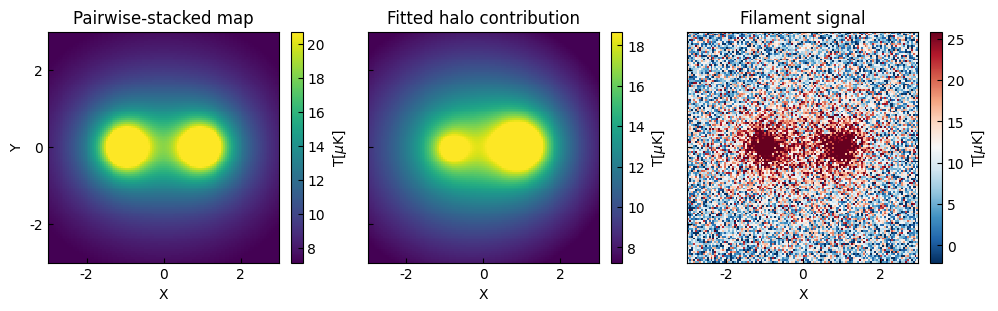

In [6]:
plot_stack_fit_residual([ex_data, ex_fit, ex_data_noise], norm='linear', cmap=['viridis', 'viridis', 'RdBu_r'])

# test gaussian sim data

In [3]:
test_data, coords = gen_test_data(noise_std=0.2, amp1=1, sigma1=0.2, amp2=1, sigma2=0.3)

## w/o mask

In [31]:
fitted, params, conv = fit_data(test_data)
res = test_data - fitted

np.float64(0.20007034122853837)

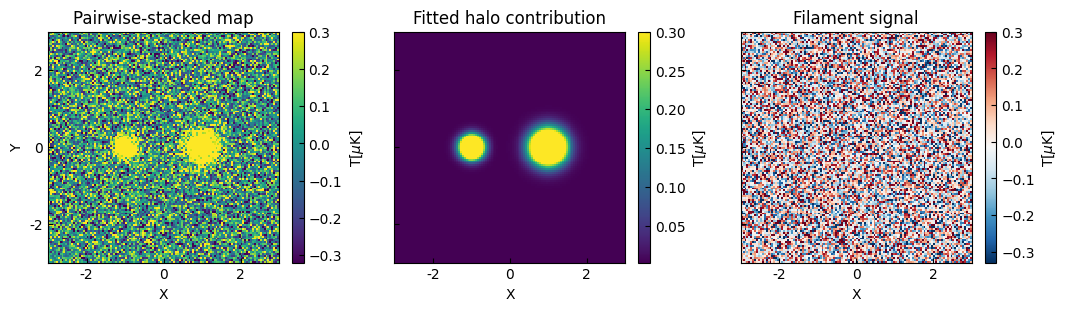

In [32]:
fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([test_data, fitted, res], norm='linear', axes=axes, cmap=['viridis', 'viridis', 'RdBu_r'], vmax=0.3)
set_ticks(axes[0], *get_ticks_labels())
np.std(res)

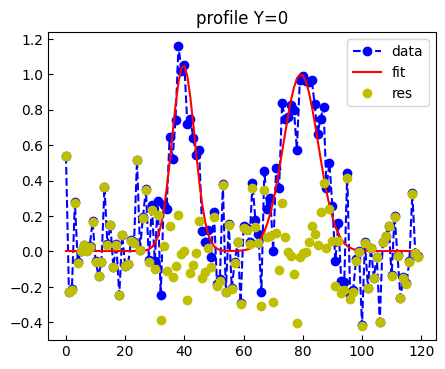

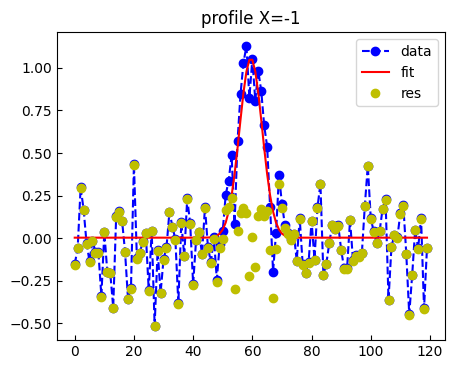

In [33]:
xx = [range(120)]*3

ind = 60
yy = [test_data[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()

ind = 40
yy = [test_data[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()

## sector mask

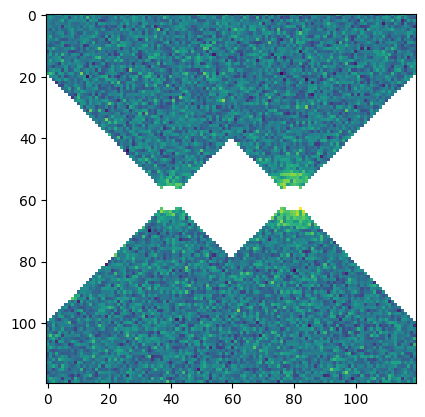

In [34]:
mask_sec4 = get_mask_sector4(coords, rlim=(0.2, 4)).reshape(test_data.shape)
plt.figure()
plt.imshow(np.ma.array(test_data, mask=~mask_sec4))

np.float64(0.20007401637827843)

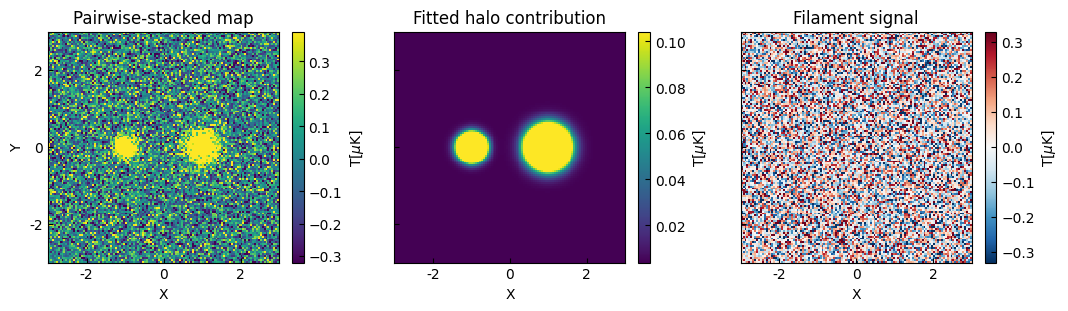

In [35]:
fitted, params, conv = fit_data(test_data, mask=mask_sec4)
res = test_data - fitted

fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([test_data, fitted, res], norm='linear', axes=axes, cmap=['viridis', 'viridis', 'RdBu_r'])
set_ticks(axes[0], *get_ticks_labels())
np.std(res)

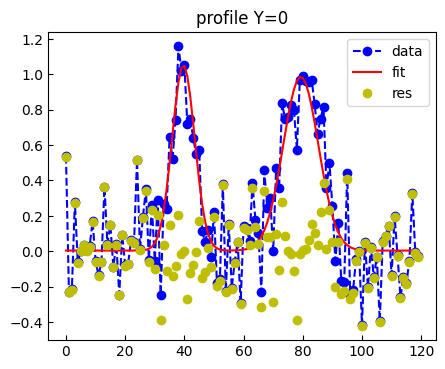

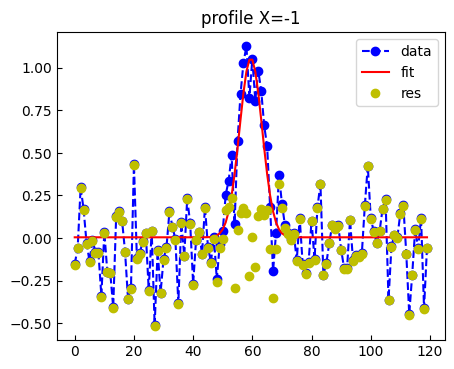

In [36]:
xx = [range(120)]*3

ind = 60
yy = [test_data[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()

ind = 40
yy = [test_data[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()

## chenck sector mask with additional peaks

In [37]:
test_data2, _ = gen_test_data(noise_std=0.2, amp1=1, sigma1=0.2, amp2=1, sigma2=0.2, center1=(2, 0), center2=(-2, 0))
test_data_com = test_data + test_data2

<Axes: title={'center': 'Heatmap'}, xlabel='X', ylabel='Y'>

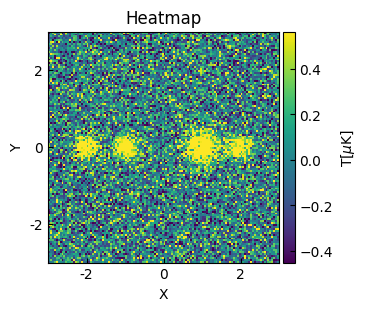

In [38]:
plot_heatmap(test_data_com, norm='linear', cmap='viridis')

np.float64(0.2936232765835215)

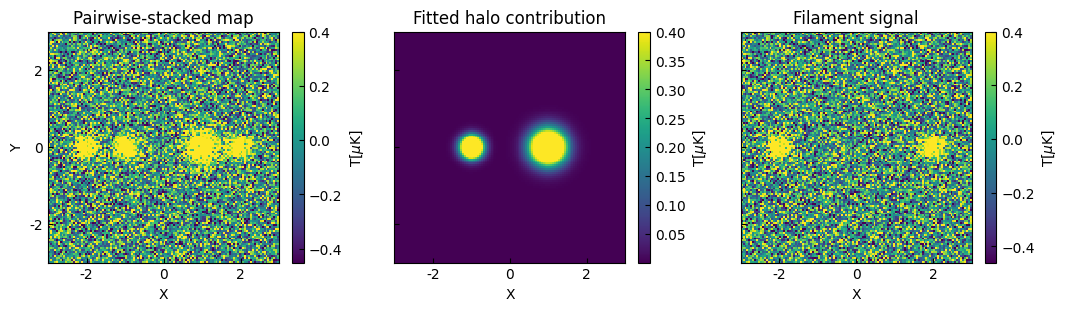

In [39]:
fitted, params, conv = fit_data(test_data_com, coords, mask=mask_sec4)
res = test_data_com - fitted

fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([test_data_com, fitted, res], norm='linear', axes=axes, cmap='viridis', vmax=0.4)
set_ticks(axes[0], *get_ticks_labels())
np.std(res)

np.float64(0.20014569557221615)

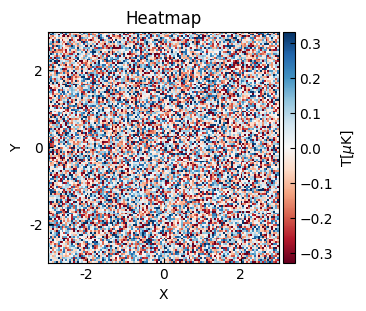

In [40]:
loss = res - test_data2
plot_heatmap(loss, norm='linear', cmap='RdBu')
np.std(loss)

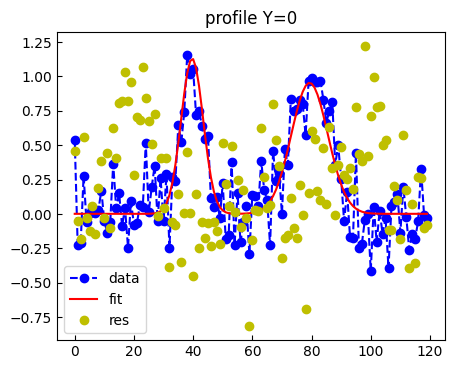

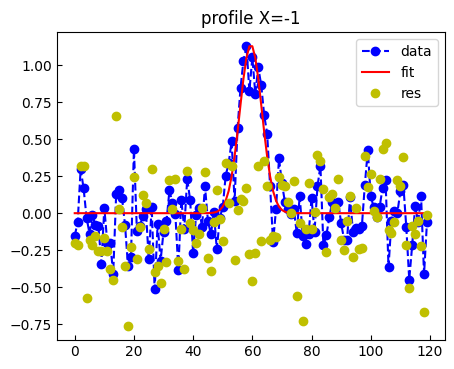

In [41]:
xx = [range(120)]*3

ind = 60
yy = [test_data[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()

ind = 40
yy = [test_data[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()

## square mask

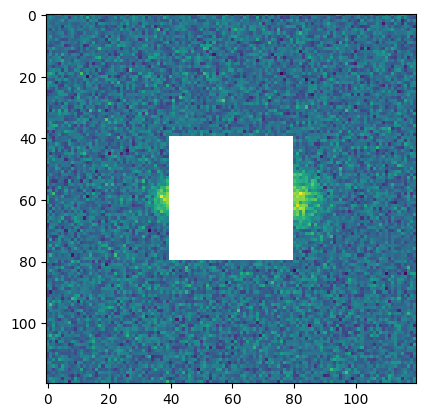

In [42]:
mask_sq = get_mask_square(coords, xlim=[-1,1], ylim=[-1,1])
plt.figure()
plt.imshow(np.ma.array(test_data, mask=mask_sq))

np.float64(0.20012520966371042)

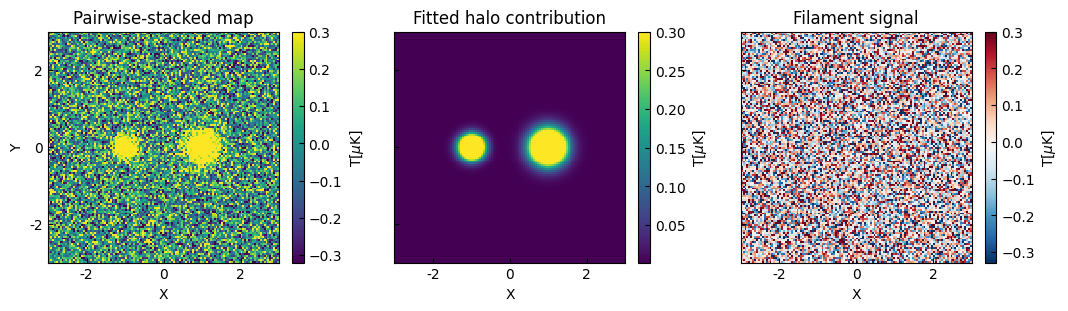

In [43]:
fitted, params, conv = fit_data(test_data, coords, mask=mask_sq)
res = test_data - fitted

fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([test_data, fitted, res], norm='linear', axes=axes, cmap=['viridis', 'viridis', 'RdBu_r'], vmax=0.3)
set_ticks(axes[0], *get_ticks_labels())
np.std(res)

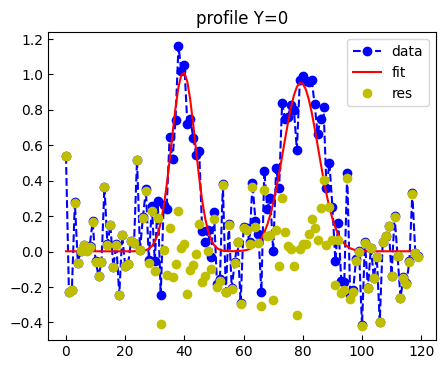

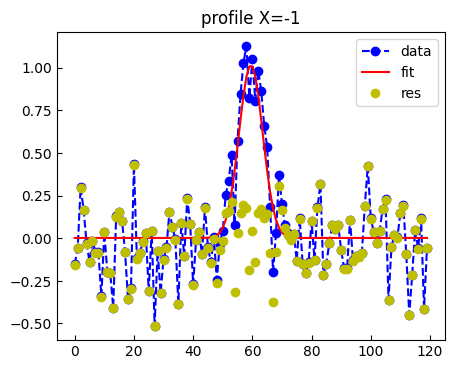

In [44]:
xx = [range(120)]*3

ind = 60
yy = [test_data[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()

ind = 40
yy = [test_data[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()

# test real data (CRAFTS arpls fourground removal)

In [45]:
from mytools.data import visititems_h5, read_h5
from mytools.plot import get_minmax

In [46]:
def mask_peak(data, fraction=0.01):
    if isinstance(data, np.ndarray):
        data = np.ma.array(data, mask=False)
    vmin, vmax = get_minmax(data, fraction)
    data[data>vmax]= vmax
    return data

In [47]:
data_path = '/home/dyliu/code/data/arpls_stack_result.h5'
visititems_h5(data_path)

stack <HDF5 dataset "stack": shape (120, 120), type "<f8">


In [48]:
stack = read_h5(data_path, 'stack') *1e6

In [22]:
# stack = mask_peak(stack)

In [49]:
mask_sec4 = get_mask_sector4(coords, rlim=(0.1, 4)).reshape(stack.shape)

## two non-identical peaks

fit params: amp1, sigma1, amp2, sigma2, offset
fit value:  [25.71045452  0.55079674 28.60792796  0.48199135 75.42324194]
fit variance:  [9.82604243e-01 2.37714187e-04 1.31168152e+00 1.90817235e-04
 1.12769549e-02]


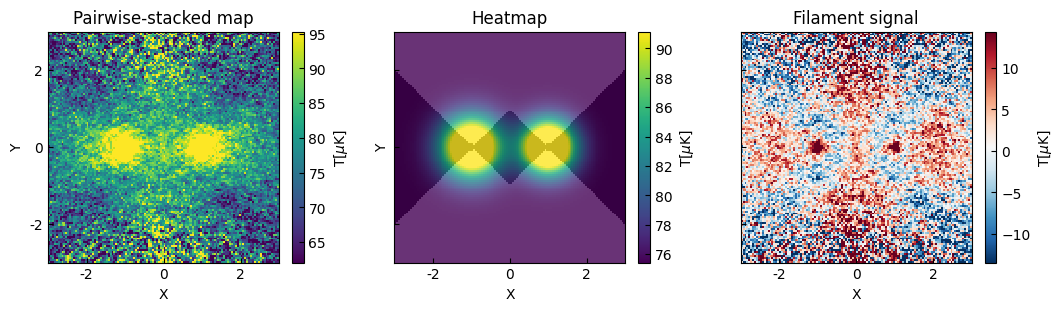

In [50]:
guess = [30, 0.5, 30, 0.5, 70]
fitted, params, conv = fit_data(stack, initial_guess=guess, mask=mask_sec4)
res = stack - fitted
print('fit params: amp1, sigma1, amp2, sigma2, offset')
print('fit value: ', params)
print('fit variance: ', np.diag(conv))

fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([stack, fitted, res], norm='linear', axes=axes, cmap=['viridis', 'viridis', 'RdBu_r'], fit_mask=mask_sec4, alpha=0.2)
set_ticks(axes[0], *get_ticks_labels())

fit residual std:  9.316027442782493


<Axes: title={'center': '(stacked - fiited)/std'}, xlabel='X', ylabel='Y'>

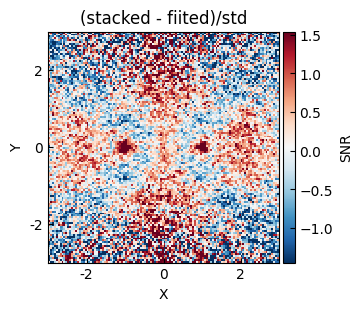

In [51]:
fit_res = stack[mask_sec4] - fitted[mask_sec4]
sigma = np.std(fit_res)
print('fit residual std: ', sigma)

plot_heatmap(res/sigma, norm='linear', cmap='RdBu_r', cbar_label='SNR', title='(stacked - fiited)/std')

(-20.0, 140.0)

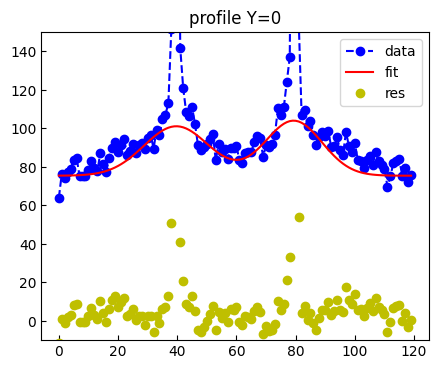

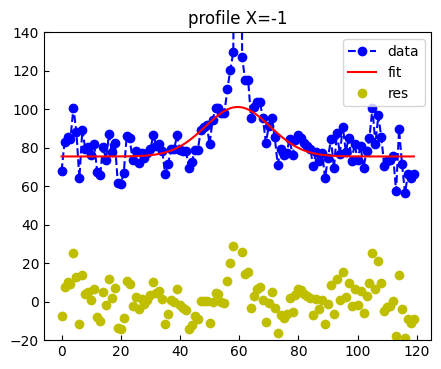

In [52]:
xx = [range(120)]*3

ind = 60
yy = [stack[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()
plt.ylim(-10, 150)

ind = 40
yy = [stack[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()
plt.ylim(-20, 140)

## two identical peaks

fit params: amp1, sigma1, amp2, sigma2, offset
fit value:  [27.51352866  0.50667849 75.46514066]
fit variance:  [5.85219302e-01 1.05308666e-04 1.11185556e-02]


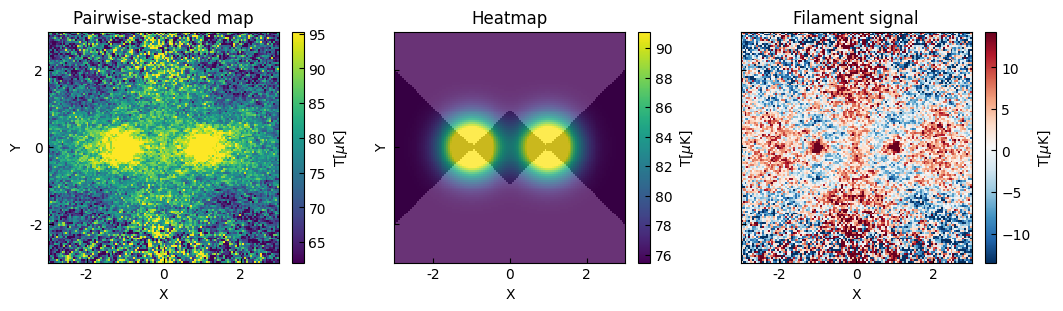

In [53]:
guess = [30, 0.5,70]
fitted, params, conv = fit_data_identical(stack, initial_guess=guess, mask=mask_sec4)
res = stack - fitted
print('fit params: amp1, sigma1, amp2, sigma2, offset')
print('fit value: ', params)
print('fit variance: ', np.diag(conv))

fig, axes= make_figure(1, 3, figsize=(13,3))
plot_stack_fit_residual([stack, fitted, res], norm='linear', axes=axes, cmap=['viridis', 'viridis', 'RdBu_r'], fit_mask=mask_sec4, alpha=0.2)
set_ticks(axes[0], *get_ticks_labels())

fit residual std:  9.317980857415032


<Axes: title={'center': '(stacked - fiited)/std'}, xlabel='X', ylabel='Y'>

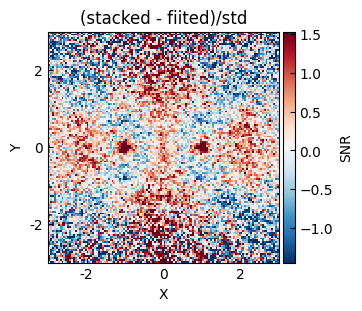

In [54]:
fit_res = stack[mask_sec4] - fitted[mask_sec4]
sigma = np.std(fit_res)
print('fit residual std: ', sigma)

plot_heatmap(res/sigma, norm='linear', cmap='RdBu_r', cbar_label='SNR', title='(stacked - fiited)/std')

(-20.0, 140.0)

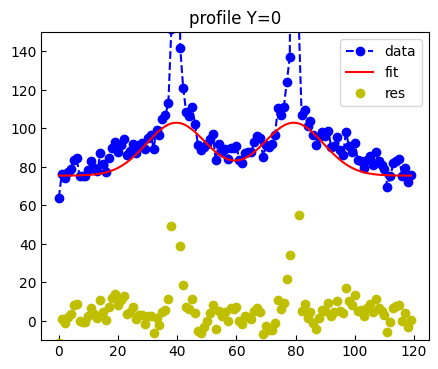

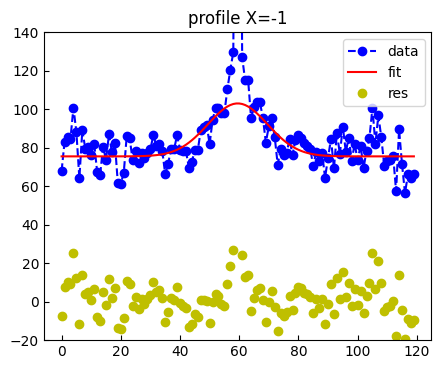

In [55]:
xx = [range(120)]*3

ind = 60
yy = [stack[ind], fitted[ind], res[ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile Y=0')
plt.legend()
plt.ylim(-10, 150)

ind = 40
yy = [stack[:, ind], fitted[:, ind], res[:, ind]]
plot_line(xx, yy, label=['data', 'fit', 'res'], marker=['o', '', 'o'], color=['b', 'r', 'y'], linestyle=['--', '-', ''])
plt.title('profile X=-1')
plt.legend()
plt.ylim(-20, 140)